# Figure 13.1 — Generation, recombination, and excess-carrier transport

Carrier lifetime controls temporal decay, diffusion length controls spatial decay, and quasi-Fermi-level splitting measures departure from equilibrium.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

diffusion length = 44.721 micrometers
largest quasi-Fermi splitting = 0.8377 eV


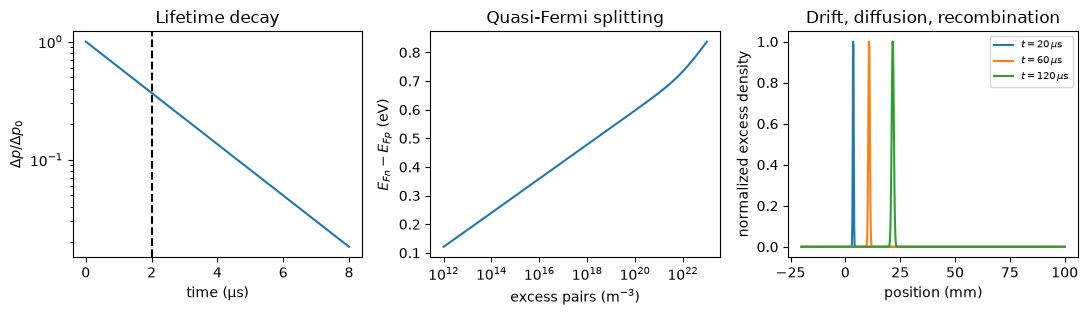

In [1]:
import numpy as np
import matplotlib.pyplot as plt

q = 1.602_176_634e-19
k_B = 1.380_649e-23
T = 300.0
V_T = k_B * T / q
n_i = 9.65e15
n_0 = 1.0e22
p_0 = n_i**2 / n_0
tau = 2.0e-6
D = 1.0e-3
L = np.sqrt(D * tau)

time = np.linspace(0.0, 8.0e-6, 500)
delta_0 = 2.0e20
delta_t = delta_0 * np.exp(-time / tau)
assert np.isclose(delta_t[np.argmin(abs(time-tau))] / delta_0, np.exp(-1), rtol=0.01)

excess = np.logspace(12.0, 23.0, 500)
n = n_0 + excess
p = p_0 + excess
splitting = V_T * np.log(n * p / n_i**2)
assert splitting[0] >= 0.0 and np.all(np.diff(splitting) > 0.0)

position = np.linspace(-0.02, 0.10, 700)
v_d = 180.0
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].semilogy(time * 1e6, delta_t / delta_0)
axes[0].axvline(tau * 1e6, ls="--", color="black")
axes[0].set(xlabel="time (µs)", ylabel=r"$\Delta p/\Delta p_0$", title="Lifetime decay")
axes[1].semilogx(excess, splitting)
axes[1].set(xlabel=r"excess pairs (m$^{-3}$)", ylabel=r"$E_{Fn}-E_{Fp}$ (eV)", title="Quasi-Fermi splitting")
for pulse_time in (20e-6, 60e-6, 120e-6):
    packet = np.exp(-(position-v_d*pulse_time)**2/(4*D*pulse_time)-pulse_time/(180e-6)) / np.sqrt(4*np.pi*D*pulse_time)
    packet /= np.max(packet)
    axes[2].plot(position * 1e3, packet, label=fr"$t={pulse_time*1e6:.0f}\,\mu$s")
axes[2].set(xlabel="position (mm)", ylabel="normalized excess density", title="Drift, diffusion, recombination")
axes[2].legend(fontsize=7)
print(f"diffusion length = {L*1e6:.3f} micrometers")
print(f"largest quasi-Fermi splitting = {splitting[-1]:.4f} eV")
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [2]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import nonequilibrium_carriers_figure

nonequilibrium_carriers_figure()
print("wrote transport-nonequilibrium-carriers.pdf")

wrote transport-nonequilibrium-carriers.pdf
